In [3]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph
from langgraph.graph import START
from langgraph.graph import END
from langgraph.graph.message import add_messages
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

In [4]:
from langchain_google_genai import ChatGoogleGenerativeAI

c:\Users\emon1\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
from dotenv import load_dotenv

load_dotenv()

True

In [8]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages: Annotated[list, add_messages]

In [9]:
@tool
def get_stock_price(symbol: str) -> float:
    '''Return the current price of a stock given the stock symbol
    :param symbol: stock symbol
    :return: current price of the stock
    '''
    return {
        "MSFT": 200.3,
        "AAPL": 100.4,
        "AMZN": 150.0,
        "RIL": 87.6
    }.get(symbol, 0.0)

In [10]:
tools = [get_stock_price]

llm = ChatGoogleGenerativeAI(model="gemini-2.0-flash")

llm_with_tools = llm.bind_tools(tools)

In [ ]:
def chatbot(state: State):
    return {'messages':[llm_with_tools.invoke(state['messages'])]}

builder = StateGraph(State)

builder.add_node(chatbot)
builder.add_node('tools',ToolNode(tools))

builder.add_edge(START, "chatbot")
builder.add_conditional_edges(
    "chatbot",
    tools_condition,
    {
        "tools": "tools",
        "__end__": END
    }
)

builder.add_edge("tools", END)

graph = builder.compile()

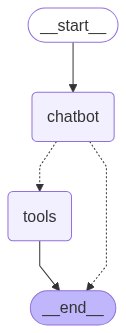

In [15]:
from IPython.display import Image
from IPython.display import display

display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
state = graph.invoke({"messages": [{"role": "user", "content": "What is the price of AAPL stock right now?"}]})

print(state["messages"][-1].content)

100.4


In [17]:
state = graph.invoke({"messages": [{"role": "user", "content": "Who invented theory of relativity? print person name only"}]})

print(state["messages"][-1].content)

Albert Einstein


In [18]:
msg = "I want to buy 20 AMZN stocks using current price. Then 15 MSFT. What will be the total cost?"

state = graph.invoke({"messages": [{"role": "user", "content": msg}]})
print(state["messages"][-1].content)

200.3
